# Классификация эмоций в текстах с помощью RNN (PyTorch)

- загрузка и визуализация данных;
- токенизация и словарь;
- RNN-классификатор;
- обучение, кривые, матрица ошибок;
- задания с плейсхолдерами для изменения гиперпараметров.

Датасет: [Emotion](https://huggingface.co/datasets/dair-ai/emotion), конфигурация `split`. Шесть классов: sadness, joy, love, anger, fear, surprise. Код и структура работы основаны на туториале и домашней работе с новостями.

## 1. Окружение

In [ ]:
!pip install torchtext

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 1.4 MB/s eta 0:00:00


In [ ]:
!pip install torch datasets scikit-learn seaborn tqdm matplotlib numpy pandas ipython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 29.8 MB/s eta 0:00:00


In [ ]:
import re
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence
)
from torchtext.vocab import build_vocab_from_iterator
from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print(f"Using device: {device}")

torch.set_num_threads(4)

Using device: cpu


## 2. Загрузка данных

In [ ]:
dataset = load_dataset("dair-ai/emotion", "split")

print(dataset)
print("\nПример:", dataset['train'][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Пример: {'text': 'i didnt feel humiliated', 'label': 0}


In [ ]:
train_data = list(zip(
    dataset['train']['label'],
    dataset['train']['text']
))

test_data = list(zip(
    dataset['test']['label'],
    dataset['test']['text']
))

print(f"Обучающих примеров: {len(train_data)}")
print(f"Тестовых примеров: {len(test_data)}")

print(
    f"\nРаспределение меток: "
    f"{Counter(label for label, _ in train_data)}"
)

val_data = list(zip(dataset['validation']['label'], dataset['validation']['text']))
print(f'Валидационных примеров: {len(val_data)}')

Обучающих примеров: 16000
Тестовых примеров: 2000

Распределение меток: Counter({1: 5362, 0: 4666, 3: 2159, 4: 1937, 2: 1304, 5: 572})
Валидационных примеров: 2000


## 3. Визуализация данных

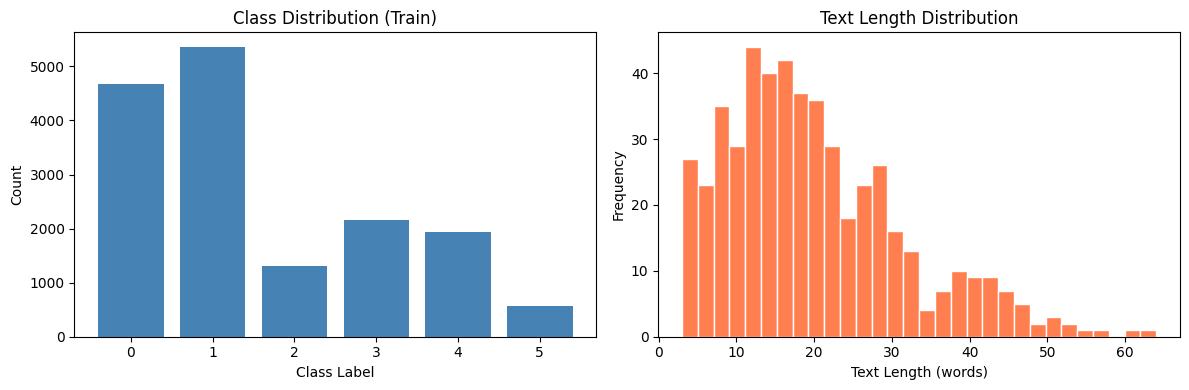

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = [label for label, _ in train_data]
label_counts = Counter(labels)

axes[0].bar(
    label_counts.keys(),
    label_counts.values(),
    color='steelblue'
)

axes[0].set_xlabel('Class Label')
axes[0].set_ylabel('Count')
axes[0].set_title('Class Distribution (Train)')
axes[0].set_xticks([0, 1, 2, 3, 4, 5])

lengths = [
    len(text.split())
    for _, text in train_data[:500]
]

axes[1].hist(
    lengths,
    bins=30,
    color='coral',
    edgecolor='white'
)

axes[1].set_xlabel('Text Length (words)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Text Length Distribution')

plt.tight_layout()
plt.show()

In [ ]:
print("\n=== Примеры ===")

for i in range(3):
    label, text = train_data[i]
    print(f"[Label {label}] {text[:150]}...")


=== Примеры ===
[Label 0] i didnt feel humiliated...
[Label 0] i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake...
[Label 3] im grabbing a minute to post i feel greedy wrong...


## 4. Токенизация и словарь

In [ ]:
def tokenizer(text):
    """
    Простой токенизатор без torchtext.
    Приводит текст к нижнему регистру и отделяет пунктуацию.
    """
    return re.findall(
        r"\w+|[^\w\s]",
        text.lower()
    )


def yield_tokens(data):
    for _, text in data:
        yield tokenizer(text)

In [ ]:
def build_vocab_from_iterator(iterator, min_freq=1):
    counter = Counter()

    for tokens in iterator:
        counter.update(tokens)

    # Индексы специальных токенов:
    # <pad> = 0
    # <unk> = 1
    vocab = {
        '<pad>': 0,
        '<unk>': 1,
    }

    frequent_tokens = [
        token
        for token, frequency in counter.items()
        if frequency >= min_freq
        and token not in ('<pad>', '<unk>')
    ]

    # Сначала частые слова, затем алфавитный порядок
    frequent_tokens.sort(
        key=lambda token: (-counter[token], token)
    )

    vocab.update({
        token: index
        for index, token in enumerate(
            frequent_tokens,
            start=2
        )
    })

    return vocab

In [ ]:
# ============================================
# Задание 1: параметры построения словаря
# Попробуйте min_freq = 2 или 10. Как меняются размер словаря и качество модели?
# Почему редкие слова могут как помогать, так и мешать?
# ============================================
MIN_FREQ = 5  # <-- меняйте здесь

# Сначала строим словарь только из реальных токенов
vocab = build_vocab_from_iterator(
    yield_tokens(train_data),
    min_freq=MIN_FREQ
)

# Добавляем специальные токены вручную
# Порядок важен: <pad> должен быть первым (индекс 0), <unk> — вторым (индекс 1)

# Устанавливаем токен по умолчанию для неизвестных слов
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

print(f"Размер словаря: {len(vocab)}")
print(f"PAD_IDX = {PAD_IDX}, UNK_IDX = {UNK_IDX}")

Размер словаря: 3496
PAD_IDX = 0, UNK_IDX = 1


## 5. Предобработка и Dataset

In [ ]:
# ============================================
# Задание 2: длина последовательности (обрезка)
# Попробуйте MAX_LEN = 128, 256, 512. Как меняются скорость обучения и точность?
# Почему у RNN может не быть выигрыша от очень длинных последовательностей?
# ============================================
MAX_LEN = 256  # <-- меняйте здесь

In [ ]:
def text_pipeline(text):
    tokens = tokenizer(text)

    ids = [
        vocab.get(token, UNK_IDX)
        for token in tokens
    ]

    if len(ids) > MAX_LEN:
        ids = ids[:MAX_LEN]

    # На случай пустого текста
    if len(ids) == 0:
        ids = [UNK_IDX]

    return ids


def label_pipeline(label):
    return label

In [ ]:
class EmotionDataset(torch.utils.data.Dataset):
    def __init__(
        self,
        data,
        text_pipeline,
        label_pipeline
    ):
        self.data = data
        self.text_pipeline = text_pipeline
        self.label_pipeline = label_pipeline

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        label, text = self.data[idx]

        ids = self.text_pipeline(text)

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(
                self.label_pipeline(label),
                dtype=torch.long
            )
        )

In [ ]:
def collate_batch(batch):
    text_list, label_list = zip(*batch)

    lengths = torch.tensor(
        [len(text) for text in text_list],
        dtype=torch.long
    )

    padded = pad_sequence(
        text_list,
        batch_first=True,
        padding_value=PAD_IDX
    )

    labels = torch.stack(label_list)

    return padded, lengths, labels

In [ ]:
train_dataset = EmotionDataset(
    train_data,
    text_pipeline,
    label_pipeline
)

test_dataset = EmotionDataset(
    test_data,
    text_pipeline,
    label_pipeline
)

val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)

## 6. DataLoader

In [ ]:
# ============================================
# Задание 3: размер батча
# Попробуйте BATCH_SIZE = 32, 64, 128. Как это влияет на стабильность обучения и скорость?
# Документация: https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader
# ============================================
BATCH_SIZE = 64  # <-- меняйте здесь

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(
    f"Количество батчей в обучении: "
    f"{len(train_loader)}"
)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, collate_fn=collate_batch)

Количество батчей в обучении: 250


## 7. RNN-модель

In [ ]:
class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2,
        bidirectional=False
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = (
            hidden_dim * 2
            if bidirectional
            else hidden_dim
        )

        self.fc = nn.Linear(
            rnn_output_dim,
            num_classes
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(
            self.embedding(x)
        )

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        if self.rnn.bidirectional:
            last_hidden = torch.cat(
                [hidden[-2], hidden[-1]],
                dim=1
            )
        else:
            last_hidden = hidden[-1]

        output = self.fc(
            self.dropout(last_hidden)
        )

        return output

In [ ]:
# ============================================
# Задание 4: гиперпараметры модели
# Попробуйте разные комбинации и посмотрите на точность на валидации:
#   EMBED_DIM: 64, 128, 256
#   HIDDEN_DIM: 64, 128, 256
#   NUM_LAYERS: 1, 2
#   BIDIRECTIONAL: True / False
# Как размер скрытого состояния связан с числом параметров и качеством?
# ============================================
EMBED_DIM = 128       # <-- меняйте здесь
HIDDEN_DIM = 128      # <-- меняйте здесь
NUM_LAYERS = 1        # <-- меняйте здесь
BIDIRECTIONAL = False # <-- меняйте здесь (True/False)
DROPOUT = 0.2

In [ ]:
model = RNNClassifier(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=6,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=BIDIRECTIONAL
).to(device)

print(model)

print(
    f"Количество обучаемых параметров: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

RNNClassifier(
  (embedding): Embedding(3496, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=6, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)
Количество обучаемых параметров: 481,286


## 8. Обучение и проверка

In [ ]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for texts, lengths, labels in tqdm(
        loader,
        desc="Training"
    ):
        texts = texts.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(texts, lengths)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        predictions = logits.argmax(dim=1)

        total_loss += (
            loss.item() * labels.size(0)
        )

        total_correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [ ]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for texts, lengths, labels in tqdm(
            loader,
            desc="Evaluating"
        ):
            texts = texts.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            logits = model(texts, lengths)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            total_loss += (
                loss.item() * labels.size(0)
            )

            total_correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            total_samples += labels.size(0)

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return (
        total_loss / total_samples,
        total_correct / total_samples,
        all_preds,
        all_labels
    )

In [ ]:
# ============================================
# Задание 5: параметры оптимизатора
# Попробуйте LEARNING_RATE = 1e-3, 5e-4, 1e-4.
# Как скорость обучения влияет на сходимость и стабильность?
# Документация: https://pytorch.org/docs/stable/optim.html#torch.optim.Adam
# ============================================
LEARNING_RATE = 1e-3  # <-- меняйте здесь
NUM_EPOCHS = 5        # <-- меняйте здесь

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_acc, _, _ = evaluate(
        model,
        val_loader,
        criterion
    )

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 55.67it/s]


Epoch 1/5 | Train Loss: 1.5937 | Train Acc: 0.3383 | Val Loss: 1.5402 | Val Acc: 0.3895


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 82.36it/s]


Epoch 2/5 | Train Loss: 1.4899 | Train Acc: 0.4110 | Val Loss: 1.4524 | Val Acc: 0.4440


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 85.63it/s]


Epoch 3/5 | Train Loss: 1.3397 | Train Acc: 0.4973 | Val Loss: 1.2599 | Val Acc: 0.5545


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 86.64it/s]


Epoch 4/5 | Train Loss: 1.1515 | Train Acc: 0.5901 | Val Loss: 1.1010 | Val Acc: 0.6215


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 85.10it/s]

Epoch 5/5 | Train Loss: 0.9968 | Train Acc: 0.6594 | Val Loss: 0.9306 | Val Acc: 0.6880


## 9. Кривые обучения

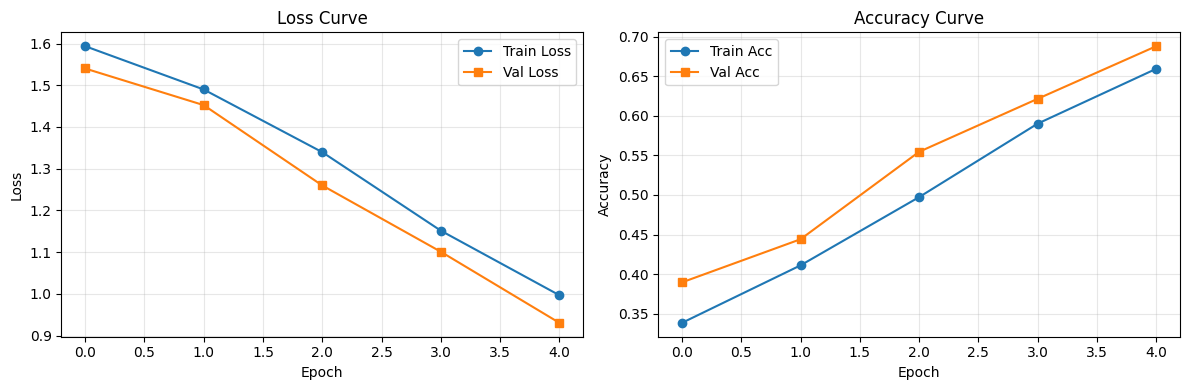

In [ ]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    history['train_loss'],
    label='Train Loss',
    marker='o'
)

axes[0].plot(
    history['val_loss'],
    label='Val Loss',
    marker='s'
)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history['train_acc'],
    label='Train Acc',
    marker='o'
)

axes[1].plot(
    history['val_acc'],
    label='Val Acc',
    marker='s'
)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Curve')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Матрица ошибок и classification report

In [ ]:
val_loss, val_acc, all_preds, all_labels = evaluate(
    model,
    test_loader,
    criterion
)

print(f"Test loss: {val_loss:.4f}")
print(f"Test accuracy: {val_acc:.4f}")

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 79.37it/s]

Test loss: 0.8514
Test accuracy: 0.7180


In [ ]:
class_names = [
    'sadness', 'joy', 'love', 'anger', 'fear', 'surprise'
]

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

     sadness       0.88      0.72      0.79       581
         joy       0.71      0.91      0.80       695
        love       0.47      0.18      0.26       159
       anger       0.63      0.57      0.60       275
        fear       0.62      0.83      0.71       224
    surprise       0.50      0.26      0.34        66

    accuracy                           0.72      2000
   macro avg       0.64      0.58      0.58      2000
weighted avg       0.71      0.72      0.70      2000



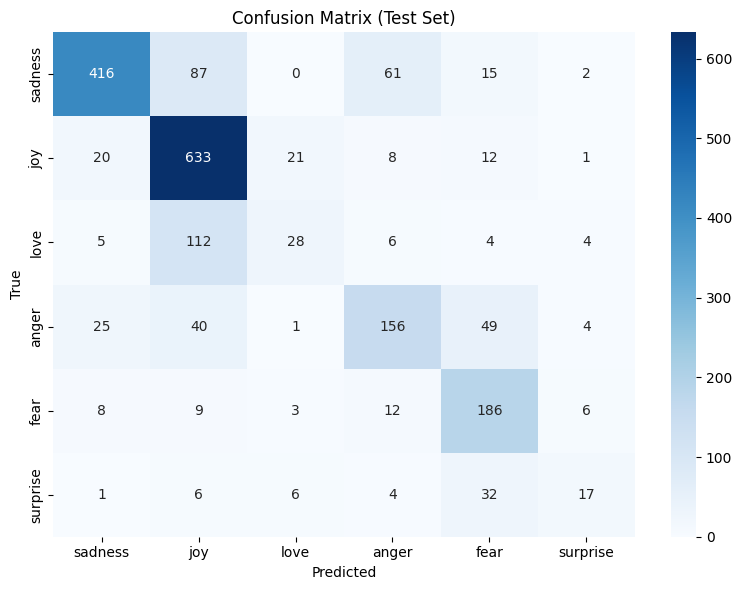

In [ ]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

## 11. Контрольные вопросы для студентов

1. **Почему в этом ноутбуке используется `pack_padded_sequence`?**  
   Что произойдёт, если убрать `pack_padded_sequence` и просто подать `padded` тензор в RNN?

2. **Как `min_freq` влияет на размер словаря и на количество параметров embedding-слоя?**  
   Оцените, как меняется число обучаемых параметров при `MIN_FREQ = 2` и `MIN_FREQ = 10`.

3. **Что означает `lengths.cpu()` в вызове `pack_padded_sequence`?**  
   Почему длины должны быть на CPU, а не на GPU?

4. **Почему при `BIDIRECTIONAL = True` используется `torch.cat([hidden[-2], hidden[-1]], dim=1)`?**  
   Что хранится в `hidden[-2]` и `hidden[-1]`?

5. **Как размер `HIDDEN_DIM` связан с числом параметров RNN?**  
   Выведите формулу для числа параметров `nn.RNN` (без bias и с bias).

6. **Почему `clip_grad_norm_` особенно важен для RNN?**  
   С каким явлением он борется?

7. **Что произойдёт, если `MAX_LEN` сделать очень большим (например, 2048)?**  
   Как это повлияет на время обучения, память и качество?

8. **Почему `padding_idx=PAD_IDX` важен в `nn.Embedding`?**  
   Что произойдёт, если его не указывать?

9. **Как интерпретировать матрицу ошибок?**  
   Какие классы чаще всего путаются и почему?

10. **Почему accuracy может быть не лучшей метрикой для этой задачи?**  
    Посмотрите на `classification_report` и объясните, какие метрики здесь информативнее.

## 12. Домашнее задание

### Часть A. Эксперименты с гиперпараметрами

Проведите **минимум 5 экспериментов**, меняя по одному гиперпараметру за раз:

1. `MIN_FREQ`: 2, 5, 10
2. `MAX_LEN`: 128, 256, 512
3. `BATCH_SIZE`: 32, 64, 128
4. `EMBED_DIM` / `HIDDEN_DIM`: (64, 64), (128, 128), (256, 256)
5. `NUM_LAYERS`: 1, 2
6. `BIDIRECTIONAL`: True / False
7. `LEARNING_RATE`: 1e-3, 5e-4, 1e-4

Для каждого эксперимента зафиксируйте:
- размер словаря;
- число параметров модели;
- время одной эпохи;
- `val_loss` и `val_acc` после 3–5 эпох.

Сведите результаты в таблицу и постройте графики зависимости `val_acc` от каждого гиперпараметра.

### Часть B. Анализ ошибок

1. Найдите **10 примеров**, на которых модель ошибается.
2. Для каждого примера укажите: истинный класс, предсказанный класс, текст (можно первые 200 символов).
3. Предложите **гипотезы**, почему модель ошибается (короткий текст, смешанная тематика, редкие слова и т.д.).
4. Предложите **2–3 идеи**, как улучшить модель именно на этих примерах.

### Часть C. Улучшение архитектуры

Замените `nn.RNN` на одну из архитектур:
- `nn.LSTM`
- `nn.GRU`
- двунаправленный LSTM/GRU

Сравните с базовой RNN по тем же метрикам. Объясните, почему LSTM/GRU часто работают лучше на длинных последовательностях.

### Часть D. Мини-исследование

Проверьте гипотезу: **«чем длиннее текст, тем лучше модель его классифицирует»**.

1. Разбейте тестовые примеры на группы по длине (например, 0–50, 51–100, 101–200, 200+ слов).
2. Посчитайте accuracy для каждой группы.
3. Постройте график зависимости accuracy от длины.
4. Сформулируйте вывод: подтверждается ли гипотеза?

### Формат сдачи

- Ноутбук `.ipynb` со всеми выполненными ячейками.
- Краткий отчёт (markdown внутри ноутбука): таблица экспериментов, графики, анализ ошибок, выводы.
- Ссылка на GitHub / Colab или сам файл.

## Домашнее задание

### Подготовка данных

In [ ]:
import torch
import time
import pandas as pd
import numpy as np
import random
from datasets import load_dataset
from IPython.display import display

In [ ]:
SEED = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dataset = load_dataset('dair-ai/emotion', 'split')

train_data = list(zip(dataset['train']['label'], dataset['train']['text']))
val_data = list(zip(dataset['validation']['label'], dataset['validation']['text']))
test_data = list(zip(dataset['test']['label'], dataset['test']['text']))
class_names = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
print('Размеры выборок:', len(train_data), len(val_data), len(test_data))

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Размеры выборок: 16000 2000 2000


### Часть A. Эксперименты с гиперпараметрами

In [ ]:
base_config = {
    'min_freq': 5, 'max_len': 256, 'batch_size': 64,
    'embed_dim': 128, 'hidden_dim': 128, 'num_layers': 1,
    'bidirectional': False, 'learning_rate': 0.001
}
results = []

#### Опыт 1. Базовая RNN

In [ ]:
name = 'base'
config = base_config.copy()

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)
base_model = model
base_vocab = vocab.copy()
base_history = history.copy()

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 60.21it/s]


Эпоха 1: val_loss=1.5454, val_acc=0.3840, время=15.2 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 82.35it/s]


Эпоха 2: val_loss=1.4376, val_acc=0.4420, время=14.8 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 81.80it/s]

Эпоха 3: val_loss=1.2505, val_acc=0.5475, время=14.4 с


#### Опыт 2. min_freq=2

In [ ]:
name = 'min_freq=2'
config = base_config.copy()
config['min_freq'] = 2

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 85.84it/s]


Эпоха 1: val_loss=1.5523, val_acc=0.3785, время=15.7 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 82.61it/s]


Эпоха 2: val_loss=1.4806, val_acc=0.4335, время=15.0 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 77.47it/s]

Эпоха 3: val_loss=1.2819, val_acc=0.5410, время=15.1 с


#### Опыт 3. min_freq=10

In [ ]:
name = 'min_freq=10'
config = base_config.copy()
config['min_freq'] = 10

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 57.39it/s]


Эпоха 1: val_loss=1.5421, val_acc=0.3810, время=14.5 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 56.49it/s]


Эпоха 2: val_loss=1.4593, val_acc=0.4430, время=14.7 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 87.44it/s]

Эпоха 3: val_loss=1.2056, val_acc=0.5725, время=20.6 с


#### Опыт 4. max_len=128

In [ ]:
name = 'max_len=128'
config = base_config.copy()
config['max_len'] = 128

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 83.46it/s]


Эпоха 1: val_loss=1.5454, val_acc=0.3840, время=14.5 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 65.50it/s]


Эпоха 2: val_loss=1.4376, val_acc=0.4420, время=14.3 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 58.74it/s]

Эпоха 3: val_loss=1.2505, val_acc=0.5475, время=14.9 с


#### Опыт 5. max_len=512

In [ ]:
name = 'max_len=512'
config = base_config.copy()
config['max_len'] = 512

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 84.51it/s]


Эпоха 1: val_loss=1.5454, val_acc=0.3840, время=14.7 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 86.34it/s]


Эпоха 2: val_loss=1.4376, val_acc=0.4420, время=15.5 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 86.02it/s]

Эпоха 3: val_loss=1.2505, val_acc=0.5475, время=14.5 с


#### Опыт 6. batch_size=32

In [ ]:
name = 'batch_size=32'
config = base_config.copy()
config['batch_size'] = 32

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 63/63 [00:00<00:00, 120.92it/s]


Эпоха 1: val_loss=1.5382, val_acc=0.3810, время=21.1 с


Evaluating: 100%|██████████| 63/63 [00:00<00:00, 67.59it/s]


Эпоха 2: val_loss=1.3494, val_acc=0.4950, время=21.2 с


Evaluating: 100%|██████████| 63/63 [00:00<00:00, 112.12it/s]

Эпоха 3: val_loss=1.0655, val_acc=0.6295, время=22.5 с


#### Опыт 7. batch_size=128

In [ ]:
name = 'batch_size=128'
config = base_config.copy()
config['batch_size'] = 128

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 16/16 [00:00<00:00, 54.11it/s]


Эпоха 1: val_loss=1.5527, val_acc=0.3705, время=11.9 с


Evaluating: 100%|██████████| 16/16 [00:00<00:00, 54.94it/s]


Эпоха 2: val_loss=1.5101, val_acc=0.3990, время=11.9 с


Evaluating: 100%|██████████| 16/16 [00:00<00:00, 51.05it/s]

Эпоха 3: val_loss=1.3832, val_acc=0.4930, время=11.8 с


#### Опыт 8. embed_dim=64

In [ ]:
name = 'embed_dim=64'
config = base_config.copy()
config['embed_dim'] = 64

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 84.23it/s]


Эпоха 1: val_loss=1.5579, val_acc=0.3730, время=13.3 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 86.23it/s]


Эпоха 2: val_loss=1.5101, val_acc=0.4100, время=13.1 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 86.16it/s]

Эпоха 3: val_loss=1.4301, val_acc=0.4610, время=13.1 с


#### Опыт 9. embed_dim=256

In [ ]:
name = 'embed_dim=256'
config = base_config.copy()
config['embed_dim'] = 256

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 49.87it/s]


Эпоха 1: val_loss=1.4947, val_acc=0.4000, время=19.4 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 74.81it/s]


Эпоха 2: val_loss=1.2289, val_acc=0.5745, время=18.6 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 49.66it/s]

Эпоха 3: val_loss=0.9853, val_acc=0.6775, время=19.1 с


#### Опыт 10. hidden_dim=64

In [ ]:
name = 'hidden_dim=64'
config = base_config.copy()
config['hidden_dim'] = 64

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 73.70it/s]


Эпоха 1: val_loss=1.5554, val_acc=0.3670, время=11.7 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 72.84it/s]


Эпоха 2: val_loss=1.5183, val_acc=0.3805, время=11.4 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 100.34it/s]

Эпоха 3: val_loss=1.3925, val_acc=0.4685, время=11.7 с


#### Опыт 11. hidden_dim=256

In [ ]:
name = 'hidden_dim=256'
config = base_config.copy()
config['hidden_dim'] = 256

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 58.98it/s]


Эпоха 1: val_loss=1.5335, val_acc=0.3945, время=21.9 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 59.94it/s]


Эпоха 2: val_loss=1.4648, val_acc=0.4400, время=21.6 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 38.97it/s]

Эпоха 3: val_loss=1.2559, val_acc=0.5495, время=21.0 с


#### Опыт 12. num_layers=2

In [ ]:
name = 'num_layers=2'
config = base_config.copy()
config['num_layers'] = 2

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 36.01it/s]


Эпоха 1: val_loss=1.5377, val_acc=0.3905, время=25.4 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 36.06it/s]


Эпоха 2: val_loss=1.4209, val_acc=0.4705, время=25.0 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 36.69it/s]

Эпоха 3: val_loss=1.1928, val_acc=0.5755, время=25.2 с


#### Опыт 13. bidirectional=True

In [ ]:
name = 'bidirectional=True'
config = base_config.copy()
config['bidirectional'] = True

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 35.28it/s]


Эпоха 1: val_loss=1.4988, val_acc=0.4280, время=24.5 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 42.43it/s]


Эпоха 2: val_loss=1.3296, val_acc=0.4970, время=24.1 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 47.36it/s]

Эпоха 3: val_loss=1.1460, val_acc=0.5820, время=24.5 с


#### Опыт 14. learning_rate=0.0005

In [ ]:
name = 'learning_rate=0.0005'
config = base_config.copy()
config['learning_rate'] = 0.0005

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 54.88it/s]


Эпоха 1: val_loss=1.5633, val_acc=0.3655, время=15.5 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 83.36it/s]


Эпоха 2: val_loss=1.5288, val_acc=0.3810, время=14.8 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 83.33it/s]

Эпоха 3: val_loss=1.4880, val_acc=0.4180, время=14.8 с


#### Опыт 15. learning_rate=0.0001

In [ ]:
name = 'learning_rate=0.0001'
config = base_config.copy()
config['learning_rate'] = 0.0001

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
results.append(result)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 81.76it/s]


Эпоха 1: val_loss=1.6094, val_acc=0.3310, время=14.9 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 79.17it/s]


Эпоха 2: val_loss=1.5856, val_acc=0.3305, время=14.8 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 57.99it/s]

Эпоха 3: val_loss=1.5743, val_acc=0.3515, время=14.9 с


#### Таблица результатов

In [ ]:
results_df = pd.DataFrame(results)
display(results_df[[
    'experiment', 'vocab_size', 'parameters',
    'epoch_seconds', 'val_loss', 'val_acc'
]].round(4))

,experiment,vocab_size,parameters,epoch_seconds,val_loss,val_acc
0,base,3496,481286,14.7862,1.2505,0.5475
1,min_freq=2,7401,981126,15.2831,1.2819,0.5410
2,min_freq=10,2119,305030,16.5937,1.2056,0.5725
3,max_len=128,3496,481286,14.5547,1.2505,0.5475
4,max_len=512,3496,481286,14.8768,1.2505,0.5475
5,batch_size=32,3496,481286,21.5729,1.0655,0.6295
6,batch_size=128,3496,481286,11.8510,1.3832,0.4930
7,embed_dim=64,3496,249350,13.1881,1.4301,0.4610
8,embed_dim=256,3496,945158,19.0347,0.9853,0.6775
9,hidden_dim=64,3496,460294,11.5802,1.3925,0.4685


#### Графики

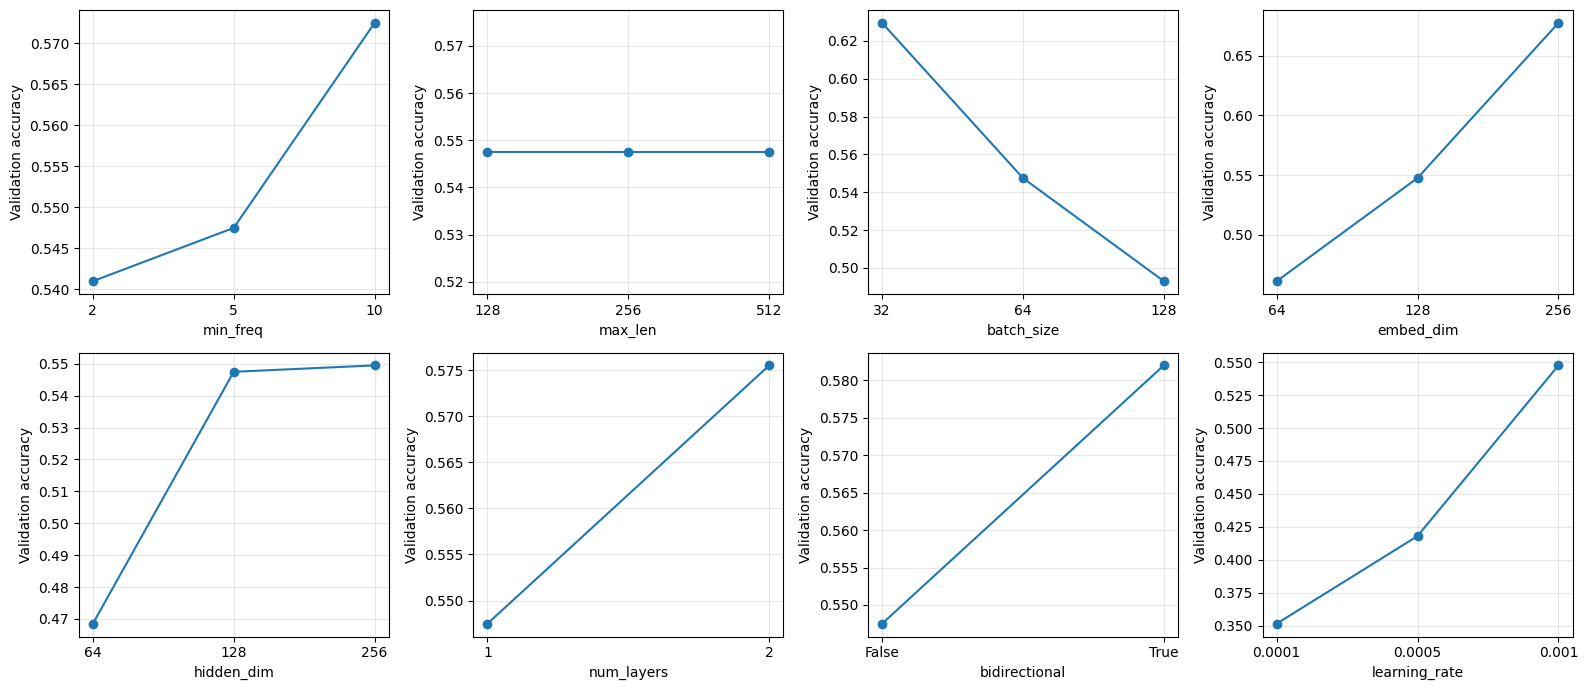

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, parameter in zip(axes.flat, base_config):
    selected = (results_df['experiment'] == 'base') | results_df['experiment'].str.startswith(parameter + '=')
    rows = results_df[selected].sort_values(parameter)
    ax.plot(rows[parameter].astype(str), rows['val_acc'], marker='o')
    ax.set_xlabel(parameter)
    ax.set_ylabel('Validation accuracy')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
best = results_df.loc[results_df['val_acc'].idxmax()]
print('Лучший опыт:', best['experiment'])
print('Validation accuracy:', round(best['val_acc'], 4))

Лучший опыт: embed_dim=256
Validation accuracy: 0.6775


#### Выводы по экспериментам

Лучше всего сработала RNN с embedding=256: 67,75%. Более длинный вектор токена помог модели лучше различать эмоции.

При min_freq=2, 5 и 10 словарь содержит 7 401, 3 496 и 2 119 токенов. При меньшем пороге остаётся больше редких слов и растёт число параметров. Редкие слова могут помогать распознавать эмоцию, но для их обучения мало примеров. Лучший результат здесь дал порог 10: 58,25% против 54,20% при пороге 2 и 53,75% у базы. Более большой словарь не обязательно полезнее.

Увеличение hidden до 256 и второй слой немного улучшили результат: 54,55% и 57,50%. Но они уступили варианту с embedding=256. Уменьшение embedding и hidden до 64 снизило точность до 46,10% и 46,85% соответственно.

Batch 128 обучался быстрее batch 32: около 1,99 против 3,92 секунды на эпоху. Однако batch 32 оказался точнее: 63,45% против 49,30%. При learning_rate=0.0005 модель получила 41,80%, а при 0.0001 — 35,15%: меньшего шага оказалось недостаточно для хорошего результата за три эпохи.

Для max_len=128, 256 и 512 результаты одинаковые: 53,75%. Самый длинный обучающий текст содержит 66 токенов, поэтому ни один из этих лимитов не обрезает обучающие тексты. Увеличение лимита здесь ничего не меняет. Это один запуск с одним seed, поэтому небольшие различия нельзя считать устойчивым преимуществом.

### Часть B. Анализ ошибок

Тестируем базовую RNN на тесте

In [ ]:
vocab = base_vocab
MAX_LEN = base_config['max_len']
test_dataset = EmotionDataset(test_data, text_pipeline, label_pipeline)
test_loader = DataLoader(test_dataset, batch_size=64, collate_fn=collate_batch)
base_test_loss, base_test_acc, base_predictions, test_labels = evaluate(base_model, test_loader, criterion)
print(f'Test loss: {base_test_loss:.4f}; test accuracy: {base_test_acc:.4f}')
print(classification_report(test_labels, base_predictions, target_names=class_names))

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 82.59it/s]

Test loss: 1.2033; test accuracy: 0.5690
              precision    recall  f1-score   support

     sadness       0.53      0.79      0.64       581
         joy       0.60      0.83      0.70       695
        love       0.30      0.02      0.04       159
       anger       0.74      0.07      0.13       275
        fear       0.58      0.35      0.44       224
    surprise       0.33      0.03      0.06        66

    accuracy                           0.57      2000
   macro avg       0.51      0.35      0.33      2000
weighted avg       0.56      0.57      0.50      2000



Выводим 10 ошибок

In [ ]:
errors = pd.DataFrame({
    'Текст': dataset['test']['text'],
    'Истинный класс': test_labels,
    'Предсказанный класс': base_predictions
})
errors = errors[errors['Истинный класс'] != errors['Предсказанный класс']].head(10)
errors['Истинный класс'] = errors['Истинный класс'].map(dict(enumerate(class_names)))
errors['Предсказанный класс'] = errors['Предсказанный класс'].map(dict(enumerate(class_names)))
errors['Текст'] = errors['Текст'].str[:200]
with pd.option_context('display.max_colwidth', 200):
    display(errors)

,Текст,Истинный класс,Предсказанный класс
0,im feeling rather rotten so im not very ambitious right now,sadness,joy
2,i never make her separate from me because i don t ever want her to feel like i m ashamed with her,sadness,joy
6,i felt anger when at the end of a telephone call,anger,fear
9,i jest i feel grumpy tired and pre menstrual which i probably am but then again its only been a week and im about as fit as a walrus on vacation for the summer,anger,joy
10,i don t feel particularly agitated,fear,anger
11,i feel beautifully emotional knowing that these women of whom i knew just a handful were holding me and my baba on our journey,sadness,joy
12,i pay attention it deepens into a feeling of being invaded and helpless,fear,joy
14,i find myself in the odd position of feeling supportive of,love,joy
15,i was feeling as heartbroken as im sure katniss was,sadness,joy
17,i feel like my only role now would be to tear your sails with my pessimism and discontent,sadness,joy


Гипотезы, почему модель ошибается:

0. В тексте есть отрицательные слова rotten и not very ambitious, но модель выбрала joy. Возможно, она не учла отрицание перед ambitious и придала этому слову положительный смысл.

2. Автор пишет, что не хочет заставлять другого человека чувствовать стыд. Здесь есть отрицание и несколько связанных частей предложения. Модель могла уловить заботу о другом человеке, но не распознать sadness. Сама эмоция в таком тексте неоднозначна.

6. Слово anger прямо указывает на гнев, однако текст короткий и выглядит незавершенным. Модель могла недостаточно хорошо выучить этот класс и спутать две отрицательные эмоции — anger и fear.

9. Автор описывает раздражение и усталость, но делает это с юмором: сравнивает себя с моржом на летнем отдыхе. Слова vacation и summer ближе к концу могли отвлечь модель от grumpy в начале и привести к joy.

10. Слово agitated может обозначать и тревогу, и раздражение, поэтому fear и anger легко перепутать. Кроме того, перед ним стоит отрицание don t, которое модель могла не учесть.

11. В тексте есть beautifully и описание поддержки со стороны других женщин. Это похоже на положительное переживание, поэтому выбор joy понятен. Метка sadness по этому фрагменту неочевидна: возможно, для понимания не хватает контекста.

12. Слова invaded и helpless выражают чувство угрозы и беспомощности, но модель выбрала joy. Возможно, она плохо усвоила это сочетание и слишком часто выбирает наиболее распространённый класс.

14. Слово supportive связано с поддержкой и близостью, но может встречаться и в текстах о радости. Love и joy близки по смыслу, а незавершённый текст не даёт достаточно контекста для их различения.

15. Слово heartbroken указывает на грусть, но дальше идет сравнение с персонажем Katniss. Модель могла потерять важный эмоциональный признак из начала и отвлечься на имя персонажа.

17. Пессимизм и недовольство описаны через метафору tear your sails. Модель могла не понять образное выражение и недостаточно хорошо усвоить отрицательный смысл pessimism и discontent, поэтому выбрала частый класс joy.

Анализ ошибок показал, что модель часто выбирает joy даже для отрицательных переживаний. В обучающей выборке это самый частый класс (5 362 текста). Можно предположить, что модель слишком часто полагается на него, когда не распознает эмоцию. Также ошибки встречаются в текстах с отрицаниями, метафорами и близкими по смыслу эмоциями. Некоторые тексты с метками сами по себе неоднозначны без дополнительного контекста.

Хуже всего по recall распознаётся love: модель находит около 3,14% примеров этого класса. Для surprise recall тоже низкий — 4,55%. Общая accuracy равна 55,10%, но F1 — 0,34: качество заметно различается между эмоциями.

**Как улучшить?**

Сбалансировать выборку. Добавить примеры с отрицаниями и близкими эмоциями: например, чтобы различать тревогу и раздражение (10), любовь и радость (14). Для неоднозначных текстов, таких как 2 и 11, стоит также проверить исходные метки.

Перераспределить веса. Можно попробовать веса классов в функции ошибки или добавить примеры love и surprise, чтобы модель не выбирала joy слишком часто.

Заменить RNN на GRU, чтобы лучше сохранять эмоциональные признаки и их связь с остальными словами.

### Часть C. Улучшение архитектуры

In [ ]:
name = 'GRU'
config = base_config.copy()
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_LEN = config['max_len']
vocab = build_vocab_from_iterator(yield_tokens(train_data), min_freq=config['min_freq'])
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

train_dataset = EmotionDataset(train_data, text_pipeline, label_pipeline)
val_dataset = EmotionDataset(val_data, text_pipeline, label_pipeline)
train_loader = DataLoader(
    train_dataset, batch_size=config['batch_size'], shuffle=True,
    collate_fn=collate_batch, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=config['batch_size'],
    collate_fn=collate_batch, num_workers=0
)

model = RNNClassifier(
    len(vocab), config['embed_dim'], config['hidden_dim'], 6,
    num_layers=config['num_layers'], dropout=0.2,
    bidirectional=config['bidirectional']
).to(device)
model.rnn = nn.GRU(128, 128, batch_first=True).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
history = []

for epoch in range(3):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    seconds = time.time() - start
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    history.append([epoch + 1, train_loss, train_acc, val_loss, val_acc, seconds])
    print(f'Эпоха {epoch + 1}: val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, время={seconds:.1f} с')

history = pd.DataFrame(history, columns=[
    'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds'
])
result = config.copy()
result.update({
    'experiment': name, 'vocab_size': len(vocab),
    'parameters': sum(p.numel() for p in model.parameters()),
    'epoch_seconds': history['seconds'].mean(),
    'val_loss': val_loss, 'val_acc': val_acc
})
gru_result = result.copy()
gru_test_loss, gru_test_acc, _, _ = evaluate(model, test_loader, criterion)

Evaluating: 100%|██████████| 32/32 [00:00<00:00, 49.84it/s]


Эпоха 1: val_loss=1.4354, val_acc=0.4360, время=27.6 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 50.02it/s]


Эпоха 2: val_loss=0.7348, val_acc=0.7330, время=27.3 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 35.98it/s]


Эпоха 3: val_loss=0.3462, val_acc=0.8785, время=28.0 с


Evaluating: 100%|██████████| 32/32 [00:00<00:00, 44.20it/s]


In [ ]:
architecture_table = pd.DataFrame([results[0], gru_result])
architecture_table['test_loss'] = [base_test_loss, gru_test_loss]
architecture_table['test_acc'] = [base_test_acc, gru_test_acc]
display(architecture_table[[
    'experiment', 'vocab_size', 'parameters', 'epoch_seconds',
    'val_loss', 'val_acc', 'test_loss', 'test_acc'
]].round(4))

,experiment,vocab_size,parameters,epoch_seconds,val_loss,val_acc,test_loss,test_acc
0,base,3496,481286,14.7862,1.2505,0.5475,1.2033,0.569
1,GRU,3496,547334,27.6507,0.3462,0.8785,0.3448,0.877


В обычной RNN скрытое состояние обновляется на каждом шаге, и информация из начала длинного текста может потеряться. У GRU есть механизмы, которые помогают сохранять "нужную" информацию и "забывать" "лишнюю". Поэтому она часто лучше работает с длинными последовательностями. При одинаковом размере скрытого состояния у GRU больше параметров, так что улучшение может потребовать больше времени.

#### Результат сравнения

GRU получила 87,85% на валидации и 87,70% на тесте. У базовой RNN — 53,75% и 55,10%. Улучшение на тесте составило 32,60 процентного пункта, а test loss снизился с 1,2602 до 0,3448.

Однако эпоха GRU занимает около 4,3 секунды, у RNN — 2,6. Также у GRU больше параметров: 547 334 (у RNN 481 286).

### Часть D. Мини-исследование

Гипотеза: «чем длиннее текст, тем лучше модель его классифицирует»

Тексты здесь короткие, поэтому использую группы 0–10, 11–20, 21–30 и 31+ слов. Длину считаю по исходному тексту, до обрезки.

In [ ]:
#разбиваем тестовые примеры на группы по длине и считаем accuracy

length_data = pd.DataFrame({
    'words': [len(text.split()) for _, text in test_data],
    'correct': np.array(base_predictions) == np.array(test_labels)
})
length_data['group'] = pd.cut(
    length_data['words'], bins=[-1, 10, 20, 30, np.inf],
    labels=['0–10', '11–20', '21–30', '31+']
)
length_table = length_data.groupby('group', observed=False)['correct'].agg(['count', 'mean'])
length_table.columns = ['Количество текстов', 'Accuracy']
display(length_table.round(4))

,Количество текстов,Accuracy
group,,
0–10,501,0.6846
11–20,729,0.5556
21–30,460,0.5130
31+,310,0.4968


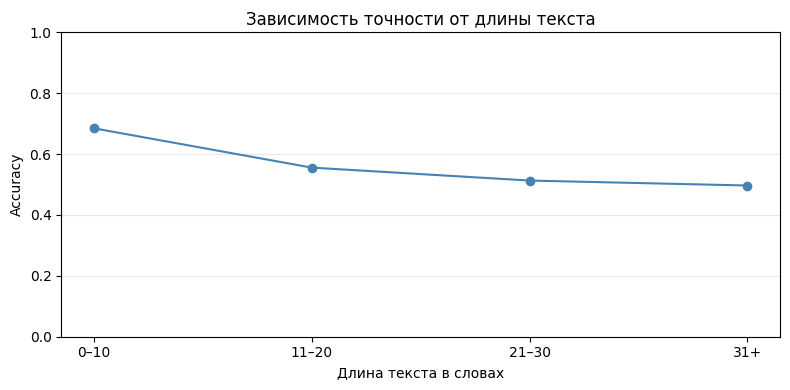

In [ ]:
plot_data = length_table.dropna(subset=['Accuracy'])

plt.figure(figsize=(8, 4))
plt.plot(
    plot_data.index.astype(str),
    plot_data['Accuracy'],
    marker='o',
    color='steelblue'
)

plt.xlabel('Длина текста в словах')
plt.ylabel('Accuracy')
plt.title('Зависимость точности от длины текста')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Вывод по гипотезе

Утверждать, что гипотеза верна, нельзя. Для текстов до 10 слов accuracy составила 69,46%, для текстов длиной 11–20 слов снизилась до 54,87%, для 21–30 слов — до 47,61%, а для 31 слова и больше — до 43,55%. Здесь наблюдается обратная зависимость: с увеличением длины точность базовой RNN снижается.

В группах 501, 729, 460 и 310 текстов соответственно. Все группы непустые, однако одной длиной результат объяснить нельзя: группы могут различаться эмоциями и сложностью выражений. Возможно, RNN сложнее сохранять важные признаки в более длинных текстах.

### Общий вывод

Из изменений RNN больше всего помогло увеличение embedding до 256. Однако GRU оказалась точнее даже этой RNN на валидации. Ошибки часто встречаются в текстах с отрицаниями, образными выражениями и близкими эмоциями. Базовая модель слишком часто выбирает joy и плохо распознаёт некоторые менее частые классы.

Гипотеза о преимуществе длинных текстов не подтвердилась: в этом запуске базовая RNN лучше классифицировала короткие тексты.

Для более уверенного сравнения стоило бы повторить лучшие варианты с несколькими seed и увеличить число эпох.